# Regularized Leapfrog

In this example we present the regularized setting of the leapfrog integrator, which implements the log-hamiltonian method of regularization by Mikkola and Tanikawa (1999). It takes constant steps in fictional time that translate to variable steps in real time depending on the potential energy in the system, making close encounters and even collisions finely resolved.

In [1]:
import rebound
import matplotlib.pyplot as plt
import numpy as np
%matplotlib inline

## 2-Body
Modleapfrog is able to integrate two-body systems without energy error even with large timesteps, though phase errors accumulate. 

In [2]:
# Setup 2 body system
sim_rlf = rebound.Simulation()

primary = rebound.Particle(m=1000.0)
sim_rlf.add(primary)
sim_rlf.add(rebound.Particle(simulation=sim_rlf, primary=primary, m=0.1, a=10, e=0.9, f=np.pi))
sim_rlf.move_to_com()

sim_ias = sim_rlf.copy()

sim_rlf.integrator = 'leapfrog'
sim_rlf.integrator.order = 4
sim_rlf.integrator.regularized = 1 # Set the mode to regularized
sim_rlf.exact_finish_time = 0 # Required for regularized integration
sim_rlf.dt = 1 # set dtau by changing the simulation dt

# Integrate a couple orbits
P = sim_rlf.orbits()[0].P
orbits = 10

t = []
E_rlf, E_ias = [], []
r_rlf, r_ias = [], []
while sim_rlf.t < orbits*P:
    sim_rlf.steps(1)
    sim_ias.integrate(sim_rlf.t)
    t.append(sim_rlf.t)
    E_rlf.append(sim_rlf.energy())
    r_rlf.append([sim_rlf.particles[1].x, sim_rlf.particles[1].y, sim_rlf.particles[1].z])
    E_ias.append(sim_ias.energy())
    r_ias.append([sim_ias.particles[1].x, sim_ias.particles[1].y, sim_ias.particles[1].z])

t = np.array(t)
E_rlf = np.array(E_rlf)
r_rlf = np.array(r_rlf)
E_ias = np.array(E_ias)
r_ias = np.array(r_ias)


Here we plot the fractional energy error of both integrations, showing that the regularized leapfrog gets to machine precision, just as IAS15.

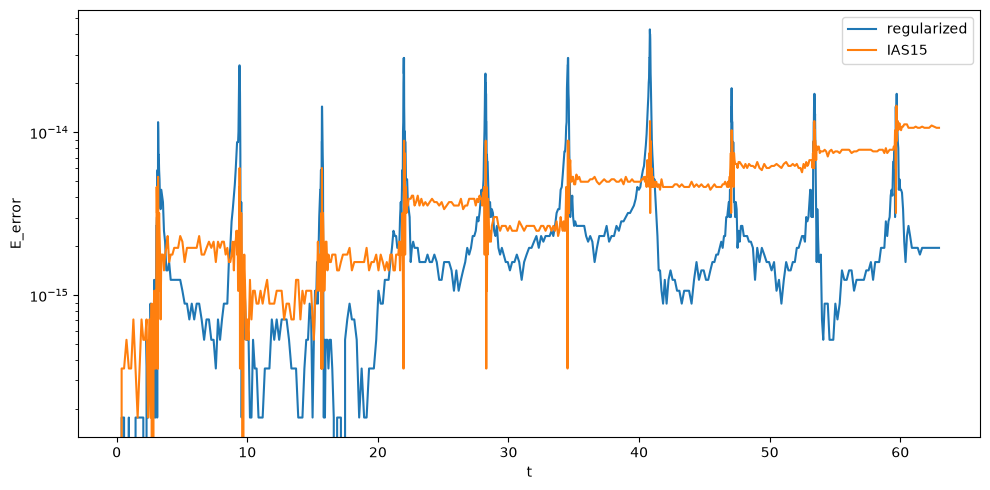

In [3]:
plt.figure(figsize=(10,5))
plt.plot(t, abs((E_rlf-E_rlf[0])/E_rlf[0]), label='regularized')
plt.plot(t, abs((E_ias-E_ias[0])/E_ias[0]), label='IAS15')
plt.semilogy()
plt.legend()
plt.xlabel('t')
plt.ylabel('E_error')
plt.tight_layout()

Here we plot the difference between the IAS15 x-coordinate (taken as ground truth) and the regularized x-coordinate, showing the phase errors accumulating.

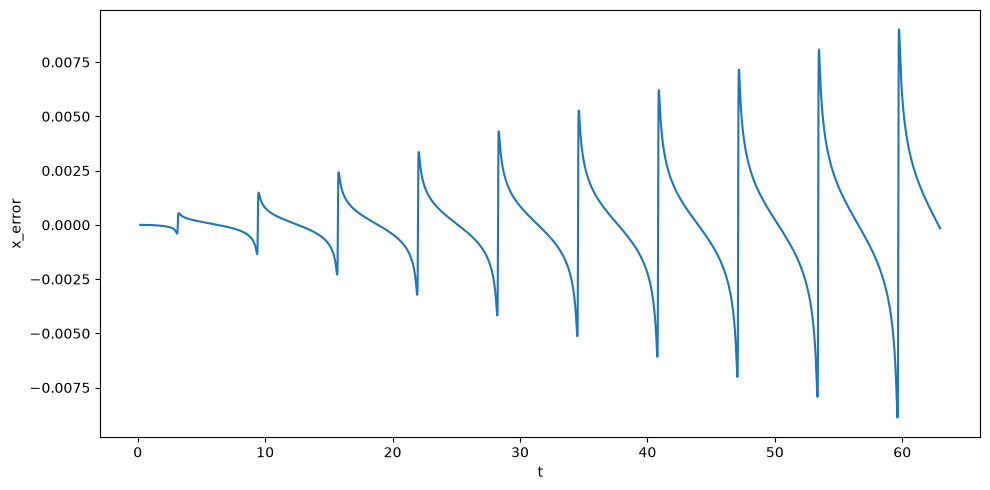

In [4]:
plt.figure(figsize=(10,5))
plt.plot(t, r_rlf[:,0] - r_ias[:,0])
plt.xlabel('t')
plt.ylabel('x_error')
plt.tight_layout()

## Collisions

The regularized integrator can also conserve energy through head-on collisions. Without collision detection, particles typically 'bounce off eachother'.

In [5]:
# Setup a linear system that collides at x=0
sim = rebound.Simulation()
sim.add(rebound.Particle(m=1.0, x=1))
sim.add(rebound.Particle(m=1.0, x=-1))

sim.integrator = 'leapfrog'
sim.integrator.order = 4
sim.integrator.regularized = 1 # Set the mode to regularized
sim.exact_finish_time = 0 # Required for regularized integration
sim.dt = 1e-1

T = 25
t = []
E = []
x1, x2 = [], []
while sim.t < T:
    sim.steps(1)
    t.append(sim.t)
    E.append(sim.energy())
    x1.append(sim.particles[0].x)
    x2.append(sim.particles[1].x)
t = np.array(t)
E = np.array(E)
x1, x2 = np.array(x1), np.array(x2)

The motion of the system, with each particle a different colour

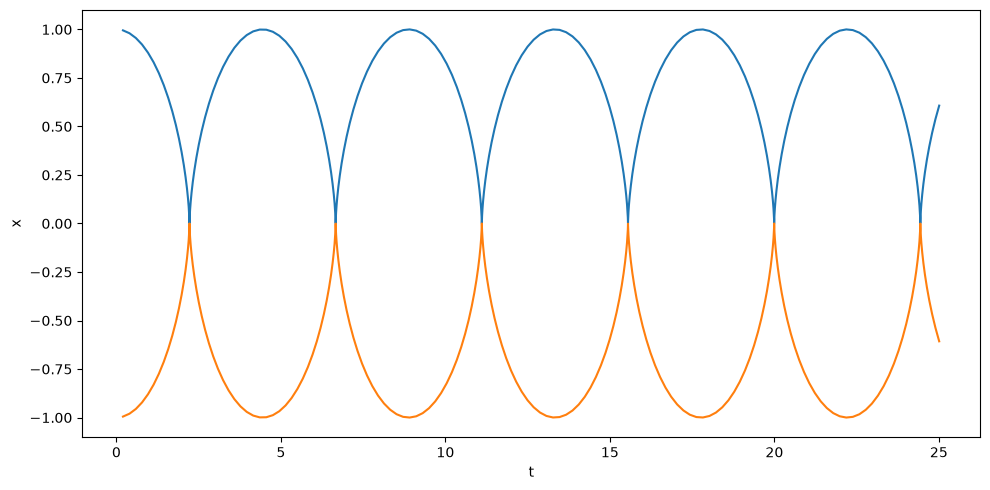

In [6]:
plt.figure(figsize=(10,5))
plt.plot(t, x1)
plt.plot(t, x2)
plt.xlabel('t')
plt.ylabel('x')
plt.tight_layout()

The fractional energy error of the system. It spikes during the collision but returns to within machine precision afterwards.

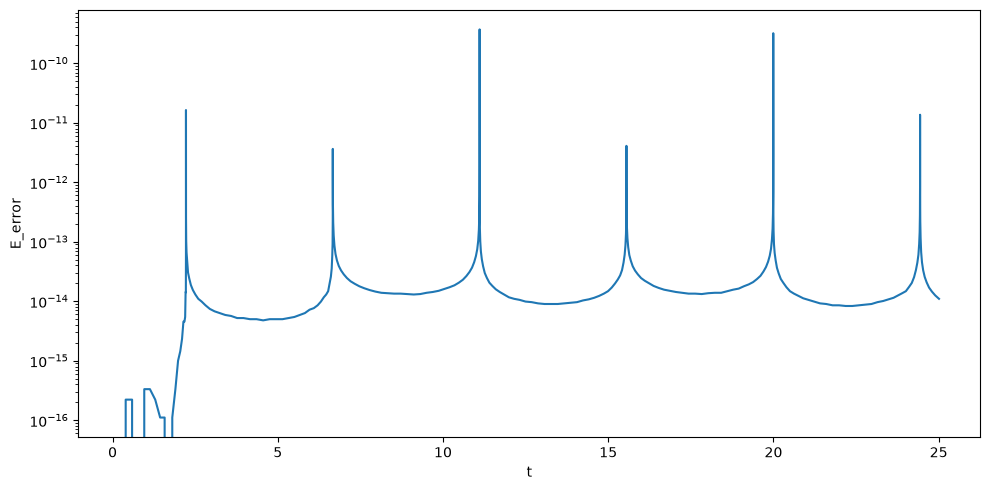

In [7]:
plt.figure(figsize=(10,5))
plt.plot(t, abs((E-E[0])/E[0]))
plt.semilogy()
plt.xlabel('t')
plt.ylabel('E_error')
plt.tight_layout()

## 3-body

We compare now with the normal leapfrog in the case of an eccentric 3-body system, where an exact solution is not trival.

In [8]:
# Setup simulations
sim = rebound.Simulation()

primary = rebound.Particle(m=1000)
sim.add(primary)
secondary = rebound.Particle(simulation=sim, primary=primary, m=0.1, a =1, e=0.99)
tertiary = rebound.Particle(simulation=sim, primary=primary, m=10.0, a =10, e=0.2)
sim.add(secondary)
sim.add(tertiary)
sim.move_to_com()

sim.integrator = 'leapfrog'
sim.integrator.order = 4

sim_lf = sim.copy()

sim.integrator.regularized = 1 # Set the mode to regularized
sim.exact_finish_time = 0 # Required for regularized integration
sim.dt = 1e-1

P = sim.orbits()[0].P
sim_lf.dt = P/50000 #Chosen to gain similar accuracy to modleapfrog

T = P * 10 #Integrate 10 periods of the eccentric planet

In [9]:
t_rlf = []
E_rlf = []
while sim.t < T:
    sim.steps(1)
    t_rlf.append(sim.t)
    E_rlf.append(sim.energy())

t_rlf = np.array(t_rlf)
E_rlf = np.array(E_rlf)

In [10]:
# ~200x slower than modleapfrog on my machine
t_lf = []
E_lf = []
while sim_lf.t < T:
    sim_lf.steps(1)
    t_lf.append(sim_lf.t)
    E_lf.append(sim_lf.energy())

t_lf = np.array(t_lf)
E_lf = np.array(E_lf)

We see that to get the same worst-case energy accuracy, regular leapfrog needs to take 25x the steps (meaning much more cpu time despite each step being faster), while being a factor of a few worse than modleapfrog for the majority of the orbit. 

# of steps by leapfrog:   500000 
# of steps by modleapfrog: 23604


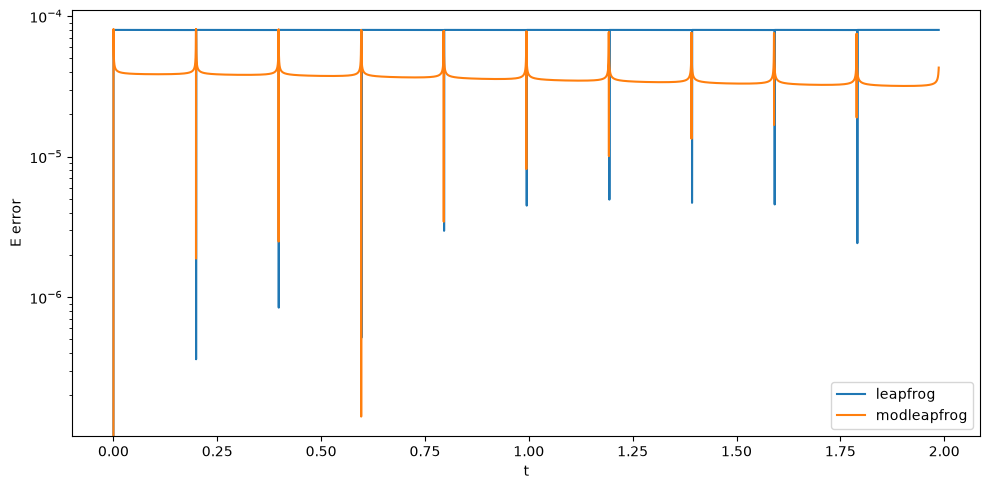

In [11]:
plt.figure(figsize=(10,5))
plt.plot(t_lf,abs((E_lf-E_lf[0])/E_lf[-1]), label ='leapfrog')
plt.plot(t_rlf,abs((E_rlf-E_rlf[0])/E_rlf[-1]), label ='modleapfrog')
plt.xlabel('t')
plt.ylabel('E error')
plt.semilogy()
plt.legend()
plt.tight_layout()
print(f'# of steps by leapfrog:   {len(t_lf)} \n# of steps by modleapfrog: {len(t_rlf)}')

## Timestep Choice

Analytically it can be shown that in a two body system, to set the number of steps in per orbit to be $N$, choose d $\tau = 2\pi m \frac{\sqrt{Ma/G}}{N}$ where $M$ is the primary mass, $m$ is the secondary mass, $a$ is the semi-major axis, and G is the gravitational constant.



In [12]:
e = 0.909
N = 500

for a in np.geomspace(1e1, 1e3, 2):
    for m in np.geomspace(1e-5, 1e-1, 2):

        sim = rebound.Simulation()
        primary = rebound.Particle(m=100.0)
        sim.add(primary)
        sim.add(rebound.Particle(simulation=sim, primary=primary, m=m, a=a, e=e, f=np.pi))

        dtau = 2* np.pi * m * np.sqrt(primary.m * a/ sim.G)/ N

        sim.integrator = 'leapfrog'
        sim.integrator.order = 4
        sim.integrator.regularized = 1
        sim.exact_finish_time = 0
        sim.dt = dtau
        sim.move_to_com()

        orbit = sim.orbits()
        P = orbit[0].P

        orbits = 10
        E_0 = sim.energy()
        sim.integrate(orbits*P, exact_finish_time=0)
        print(f'm = {m:.2e}, a = {a:.2e}')
        print(f'#steps/orbit = {sim.steps_done/orbits}')
        print(f'Energy error: {abs((sim.energy() - E_0) / E_0):.4e}')
        print()

m = 1.00e-05, a = 1.00e+01
#steps/orbit = 500.0
Energy error: 7.4539e-15

m = 1.00e-01, a = 1.00e+01
#steps/orbit = 499.8
Energy error: 8.6597e-15

m = 1.00e-05, a = 1.00e+03
#steps/orbit = 500.0
Energy error: 2.1176e-16

m = 1.00e-01, a = 1.00e+03
#steps/orbit = 499.8
Energy error: 2.6021e-15

